# Problem sheet 7 (Exercise 7)

**34.** The gradient algorithm with Armijo step size rule should be employed for the minimization of the Rosenbrock function

$$f(x_1, x_2) = (1 - x_1)^2 + 100(x_2 - x_1^2)^2$$

with $x^0 = (-1.2, 1)^T$, $\sigma = 10^{-4}$, and $\beta = 0.5$. How many iterations are needed to fulfill the stopping criterion

$$\|\nabla f(x^k)\| \le \varepsilon$$

when $\varepsilon$ takes the values $10^{-1}, \dots, 10^{-5}$? Provide a graphical representation of the implementation history. Provide the vector $x^{STOP}$ at which the algorithm stops and the value of the distance from $x^{STOP}$ to the global minimum $x^* = (1, 1)^T$ of $f$.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [19]:
# Rosenbrock function and its gradient
def rosenbrock(v):
    x, y = v
    f = (1 - x)**2 + 100*(y - x**2)**2
    return f

def grad_rosenbrock(v):
    x, y = v
    grad_f = np.array([
        -2*(1 - x) - 400*x*(y - x**2),
        200*(y - x**2)
    ])
    return grad_f

In [20]:
def gradient_algorithm_armijo(f, grad_f, x0, epsilon, sigma, beta):
    x_k = x0
    k = 0  # num of iterations
    vectors = []
    vectors.append(x0)

    while np.linalg.norm(grad_f(x_k)) > epsilon:
        d_k = - grad_f(x_k)

        t_k = 1
        while f(x_k + t_k*d_k) > f(x_k) + sigma*t_k*np.dot(grad_f(x_k),d_k):
            t_k *= beta
        
        x_k = x_k + t_k * d_k
        k += 1
        vectors.append(x_k)

    return x_k, vectors, k

In [39]:
x0 = [-1.2, 1]
sigma = 1e-4
beta = 0.5
epsilons = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]

x_ks = []
vectors = []
num_it = []

    
for eps in epsilons:
    x, vec, k = gradient_algorithm_armijo(rosenbrock, grad_rosenbrock, x0, eps, sigma, beta)
    x_ks.append(x)
    num_it.append(k)


# distances to the global minimum 
dist = []
x_min = np.array([1, 1])
for x in x_ks:
    d = np.linalg.norm(x_min- x)
    dist.append(d)



data = {
    "Epsilon": epsilons,
    "Last approximation": x_ks,
    "Number of iterations": num_it,
    "Distance from the glob. min.": dist
    }
df = pd.DataFrame(data)
df

,Epsilon,Last approximation,Number of iterations,Distance from the glob. min.
0,0.10000,"[0.931027, 0.866365]",54,0.150384
1,0.01000,"[0.99213, 0.984306]",2435,0.017557
2,0.00100,"[0.99921, 0.998418]",5231,0.001768
3,0.00010,"[0.999921, 0.999841]",8058,0.000178
4,0.00001,"[0.999992, 0.999984]",10916,0.000018


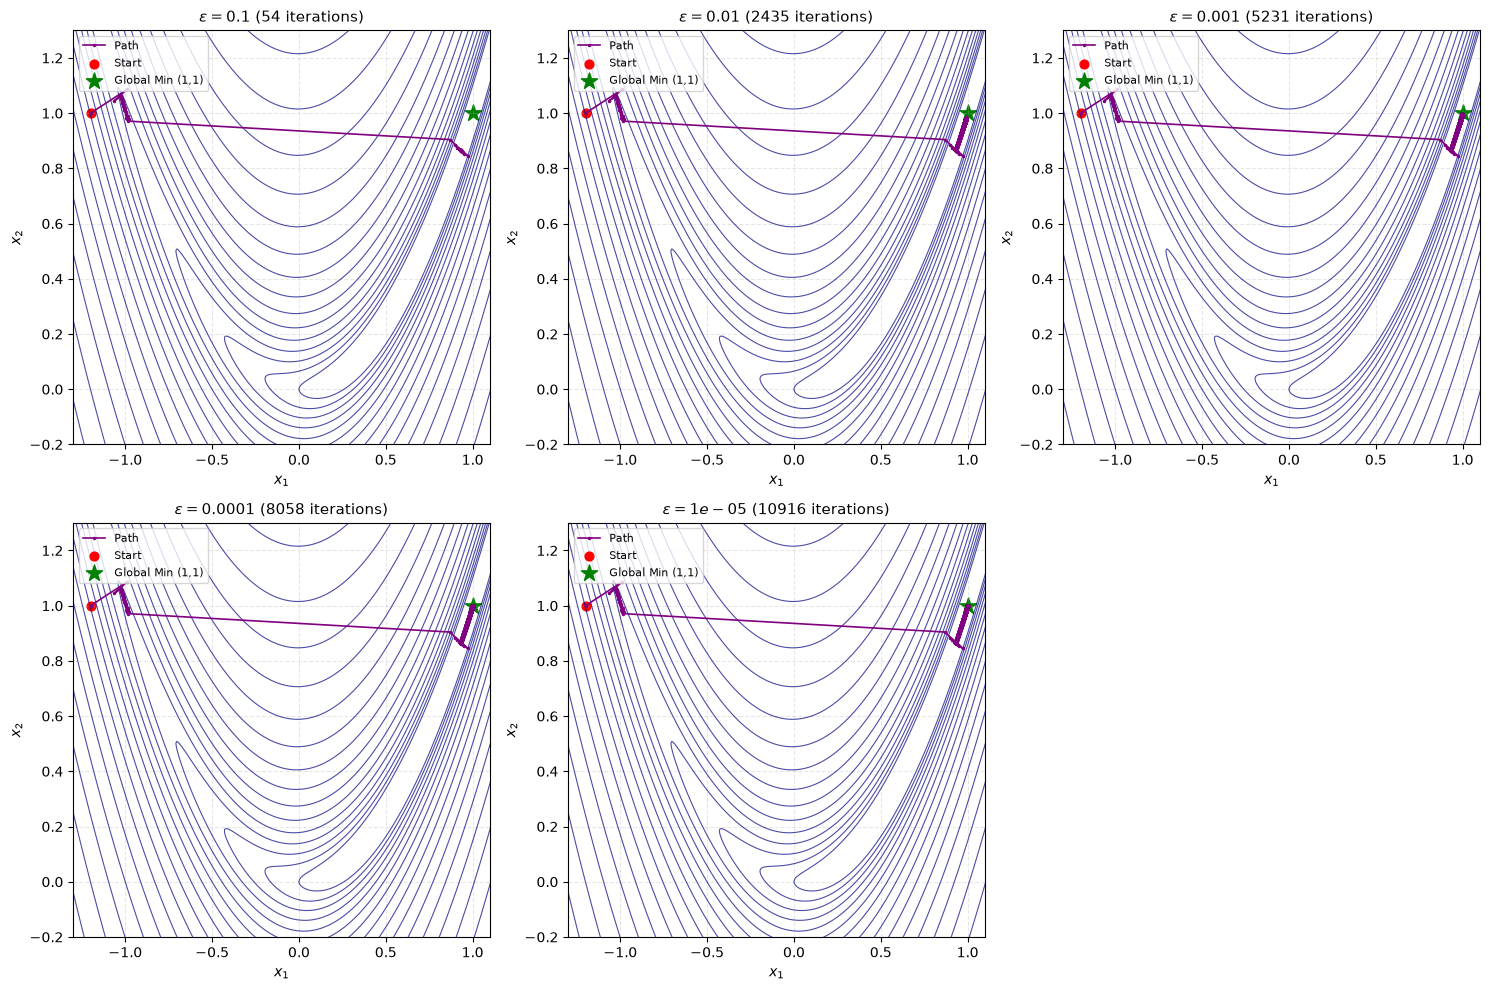

In [34]:
import matplotlib.pyplot as plt


x_vals = np.linspace(-1.5, 1.5, 400)
y_vals = np.linspace(-0.5, 2.0, 400)
X, Y = np.meshgrid(x_vals, y_vals)
Z = (1 - X)**2 + 100 * (Y - X**2)**2
levels = np.logspace(0, 4.5, 30)


fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()  


for i, eps in enumerate(epsilons):
    ax = axes[i]
    contour = ax.contour(X, Y, Z, levels=levels, cmap='jet', linewidths=0.8, alpha=0.7)
    x_end, vectors, num_it = gradient_algorithm_armijo(rosenbrock, grad_rosenbrock, x0, eps, sigma, beta)
    vec_arr = np.array(vectors)
    ax.plot(vec_arr[:, 0], vec_arr[:, 1], color='purple', linewidth=1.2, marker='.', markersize=3, label='Path')
    ax.scatter(vec_arr[0, 0], vec_arr[0, 1], color='red', marker='o', s=40, label='Start')
    ax.scatter(1.0, 1.0, color='green', marker='*', s=150, label='Global Min (1,1)')
    ax.set_title(f'$\\varepsilon = {eps}$ ({num_it} iterations)', fontsize=11)
    ax.set_xlabel('$x_1$', fontsize=10)
    ax.set_ylabel('$x_2$', fontsize=10)
    ax.set_xlim(-1.3, 1.1)
    ax.set_ylim(-0.2, 1.3)
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.3)

fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()